# Diabetes Diagnosis Intelligent System

This notebook builds an intelligent system for diabetes diagnosis using Pima Indians Diabetes Database.

## System Definition

**Task (T):** Diagnose whether a patient has diabetes based on diagnostic measurements.
**Experience (E):** A dataset of female patients at least 21 years old of Pima Indian heritage.
**Performance Measure (P):** Accuracy, Precision, Recall, F1-Score, and ROC-AUC.

## System Diagram

Data Collection -> Preprocessing (KNN Imputation, Scaling) -> Model Training (LR, KNN, DT, SVM) -> Evaluation -> Best Model Selection -> Deployment

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, roc_curve

In [2]:
dataset_path = Path.cwd() / 'DATA' / 'diabetes_dataset.csv'
# Fallback if running from outside assign1
if not dataset_path.exists():
    dataset_path = Path('/home/dau/AI/assign1/DATA/diabetes_dataset.csv')
print(f"Dataset path: {dataset_path}")

Dataset path: /home/dau/AI/assign1/DATA/diabetes_dataset.csv


In [3]:
df = pd.read_csv(dataset_path)
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## Dataset Description

| Feature | Description |
|---|---|
| Pregnancies | Number of times pregnant |
| Glucose | Plasma glucose concentration a 2 hours in an oral glucose tolerance test |
| BloodPressure | Diastolic blood pressure (mm Hg) |
| SkinThickness | Triceps skin fold thickness (mm) |
| Insulin | 2-Hour serum insulin (mu U/ml) |
| BMI | Body mass index (weight in kg/(height in m)^2) |
| DiabetesPedigreeFunction | Diabetes pedigree function |
| Age | Age (years) |
| Outcome | Class variable (0 or 1) |

In [4]:
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nData Types:\n", df.dtypes)

Shape: (768, 9)

Columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Data Types:
 Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [6]:
class_counts = df['Outcome'].value_counts()
class_pct = df['Outcome'].value_counts(normalize=True) * 100
pd.DataFrame({'Count': class_counts, 'Percentage (%)': class_pct})

,Count,Percentage (%)
Outcome,,
0,500,65.104167
1,268,34.895833


## Data Quality Analysis

Many features (Glucose, BloodPressure, SkinThickness, Insulin, BMI) have 0 values which are biologically impossible. These represent missing values and need to be handled.

In [7]:
zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
zero_counts = (df[zero_cols] == 0).sum()
zero_pct = (zero_counts / len(df)) * 100
pd.DataFrame({'Zero Count': zero_counts, 'Zero Percentage (%)': zero_pct})

,Zero Count,Zero Percentage (%)
Glucose,5,0.651042
BloodPressure,35,4.557292
SkinThickness,227,29.557292
Insulin,374,48.697917
BMI,11,1.432292


In [8]:
df_clean = df.copy()
df_clean[zero_cols] = df_clean[zero_cols].replace(0, np.nan)
print("Missing values after replacement:\n", df_clean.isna().sum())

Missing values after replacement:
 Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


## Data Representation

Using all 8 features. Let $X \in \mathbb{R}^{m \times 8}$ be the feature matrix and $y \in \{0, 1\}^m$ be the target vector.

We use `KNNImputer(n_neighbors=5)` instead of `SimpleImputer` because KNN can capture relationships between features (e.g., Insulin and Glucose are related) to provide more accurate imputations than simple median replacement.

In [9]:
FEATURES = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
TARGET = 'Outcome'

X = df_clean[FEATURES]
y = df_clean[TARGET]

In [10]:
correlations = df_clean.corr()[TARGET].sort_values(ascending=False).drop(TARGET)
print("Correlation with Outcome:\n")
for feature, corr in correlations.items():
    bar = '|' * int(abs(corr) * 50)
    sign = '+' if corr > 0 else '-'
    print(f"{feature:25} {corr:6.3f} {sign} {bar}")

Correlation with Outcome:

Glucose                    0.495 + ||||||||||||||||||||||||
BMI                        0.314 + |||||||||||||||
Insulin                    0.303 + |||||||||||||||
SkinThickness              0.259 + ||||||||||||
Age                        0.238 + |||||||||||
Pregnancies                0.222 + |||||||||||
DiabetesPedigreeFunction   0.174 + ||||||||
BloodPressure              0.171 + ||||||||


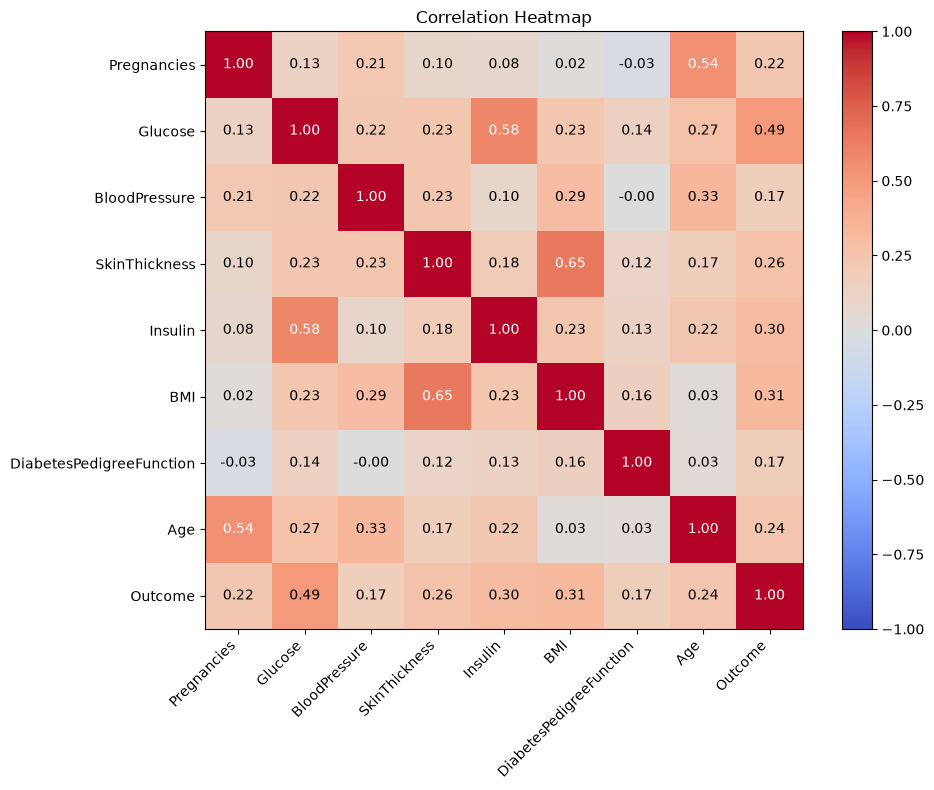

In [11]:
corr_matrix = df_clean.corr()
fig, ax = plt.subplots(figsize=(10, 8))
cax = ax.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
fig.colorbar(cax)

ax.set_xticks(np.arange(len(corr_matrix.columns)))
ax.set_yticks(np.arange(len(corr_matrix.columns)))
ax.set_xticklabels(corr_matrix.columns, rotation=45, ha='right')
ax.set_yticklabels(corr_matrix.columns)

for i in range(len(corr_matrix.columns)):
    for j in range(len(corr_matrix.columns)):
        text = ax.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}",
                       ha="center", va="center", color="black" if abs(corr_matrix.iloc[i, j]) < 0.5 else "white")

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

## Exploratory Data Analysis (EDA)

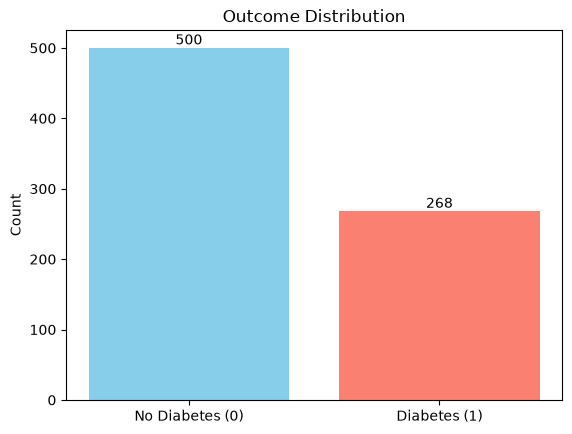

In [12]:
fig, ax = plt.subplots()
counts = y.value_counts()
ax.bar(['No Diabetes (0)', 'Diabetes (1)'], counts.values, color=['skyblue', 'salmon'])
for i, v in enumerate(counts.values):
    ax.text(i, v + 5, str(v), ha='center')
plt.title('Outcome Distribution')
plt.ylabel('Count')
plt.show()

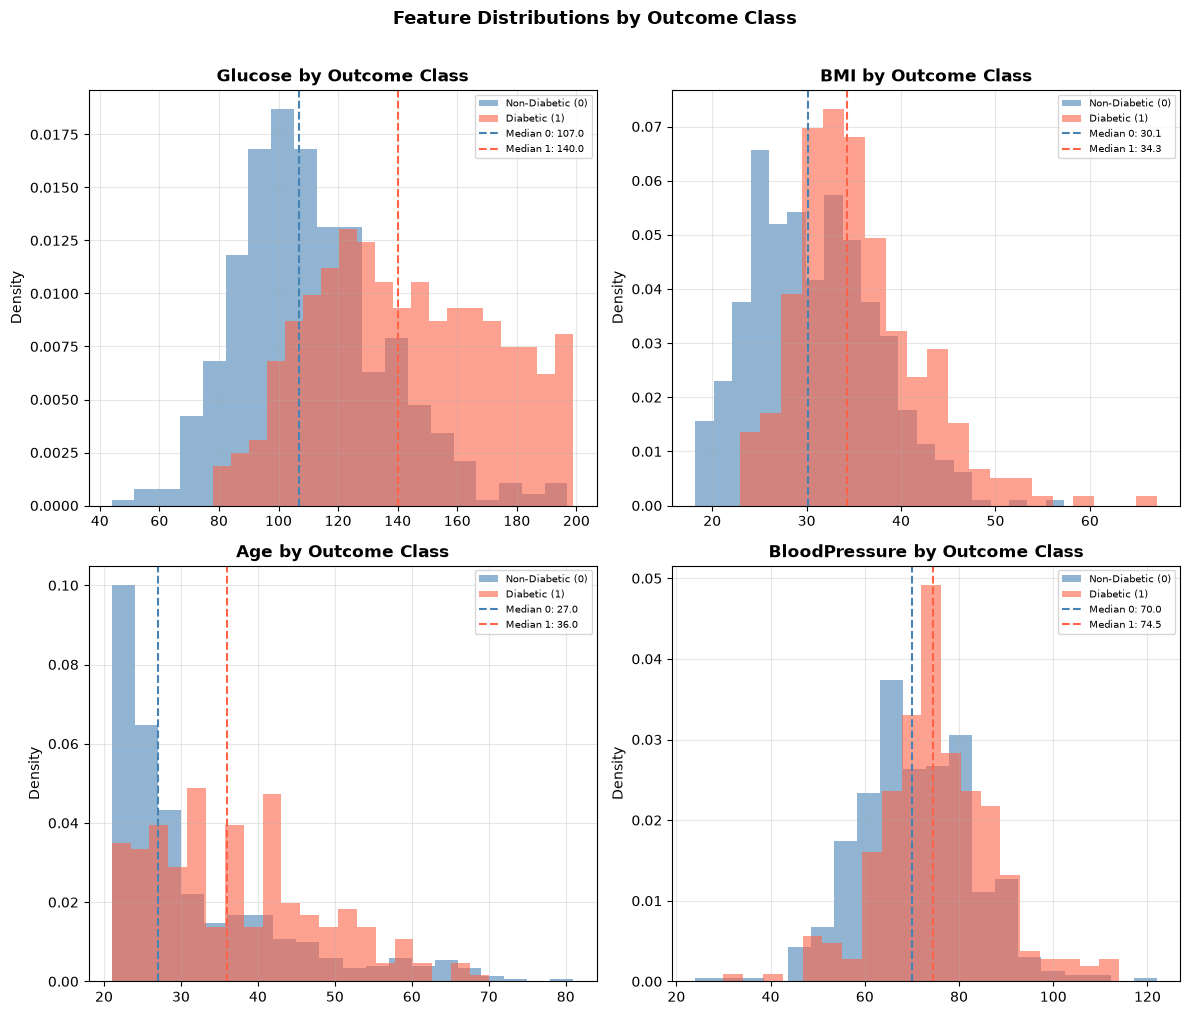

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
features_to_plot = ['Glucose', 'BMI', 'Age', 'BloodPressure']

for i, feature in enumerate(features_to_plot):
    row, col = i // 2, i % 2
    data_0 = df_clean[df_clean[TARGET]==0][feature].dropna()
    data_1 = df_clean[df_clean[TARGET]==1][feature].dropna()
    axes[row, col].hist(data_0, bins=20, alpha=0.6, color='steelblue', label='Non-Diabetic (0)', density=True)
    axes[row, col].hist(data_1, bins=20, alpha=0.6, color='tomato', label='Diabetic (1)', density=True)
    axes[row, col].axvline(data_0.median(), color='steelblue', linestyle='--', linewidth=1.5, label=f'Median 0: {data_0.median():.1f}')
    axes[row, col].axvline(data_1.median(), color='tomato', linestyle='--', linewidth=1.5, label=f'Median 1: {data_1.median():.1f}')
    axes[row, col].set_title(f'{feature} by Outcome Class', fontweight='bold')
    axes[row, col].set_ylabel('Density')
    axes[row, col].legend(fontsize=7)
    axes[row, col].grid(alpha=0.3)

plt.suptitle('Feature Distributions by Outcome Class', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### EDA Observations
- Glucose and BMI show a clear difference in distributions between classes, making them strong predictors.
- Age shows that younger people have fewer cases of diabetes in this dataset.
- BloodPressure distributions heavily overlap between classes.

## Data Splitting
Stratified 80/20 split to maintain class ratios.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Training set shape:", X_train.shape, y_train.shape)
print("Test set shape:", X_test.shape, y_test.shape)

Training set shape: (614, 8) (614,)
Test set shape: (154, 8) (154,)


## Preprocessing Pipeline
Using KNNImputer with 5 neighbors and StandardScaler.

In [15]:
preprocessor = Pipeline([
    ('imputer', KNNImputer(n_neighbors=5)),
    ('scaler', StandardScaler())
])
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

## Baseline Model

In [16]:
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train_processed, y_train)
y_pred_dummy = dummy.predict(X_test_processed)
print(classification_report(y_test, y_pred_dummy, zero_division=0))

              precision    recall  f1-score   support

           0       0.65      1.00      0.79       100
           1       0.00      0.00      0.00        54

    accuracy                           0.65       154
   macro avg       0.32      0.50      0.39       154
weighted avg       0.42      0.65      0.51       154



In [17]:
def evaluate_model(model, X_test, y_test, name="Model"):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else model.decision_function(X_test)
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)
    
    print(f"--- {name} ---")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    print(f"ROC-AUC:   {auc:.4f}\n")
    
    return {'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1': f1, 'AUC': auc}

## Logistic Regression

In [18]:
lr = LogisticRegression(random_state=42, max_iter=1000)
lr.fit(X_train_processed, y_train)
res_lr = evaluate_model(lr, X_test_processed, y_test, "Logistic Regression")

--- Logistic Regression ---
Accuracy:  0.6948
Precision: 0.5745
Recall:    0.5000
F1-Score:  0.5347
ROC-AUC:   0.8137



## K-Nearest Neighbors

In [19]:
knn = KNeighborsClassifier()
knn.fit(X_train_processed, y_train)
res_knn = evaluate_model(knn, X_test_processed, y_test, "KNN")

--- KNN ---
Accuracy:  0.7338
Precision: 0.6226
Recall:    0.6111
F1-Score:  0.6168
ROC-AUC:   0.7787



## Decision Tree

In [20]:
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train_processed, y_train)
res_dt = evaluate_model(dt, X_test_processed, y_test, "Decision Tree")

--- Decision Tree ---
Accuracy:  0.7143
Precision: 0.5781
Recall:    0.6852
F1-Score:  0.6271
ROC-AUC:   0.7076



## Support Vector Machine (SVM)

In [21]:
svm = SVC(probability=True, random_state=42)
svm.fit(X_train_processed, y_train)
res_svm = evaluate_model(svm, X_test_processed, y_test, "SVM")

--- SVM ---
Accuracy:  0.7338
Precision: 0.6444
Recall:    0.5370
F1-Score:  0.5859
ROC-AUC:   0.7972



/home/dau/.conda/envs/assignment01/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


## Hyperparameter Tuning with GridSearchCV
We tune Logistic Regression and SVM models.

In [22]:
param_grid_lr = {'C': [0.01, 0.1, 1, 10, 100], 'penalty': ['l2']}
grid_lr = GridSearchCV(LogisticRegression(random_state=42, max_iter=1000), param_grid_lr, cv=5, scoring='f1')
grid_lr.fit(X_train_processed, y_train)
print("Best LR Params:", grid_lr.best_params_)

/home/dau/.conda/envs/assignment01/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


/home/dau/.conda/envs/assignment01/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/dau/.conda/envs/assignment01/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/dau/.conda/e

/home/dau/.conda/envs/assignment01/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


/home/dau/.conda/envs/assignment01/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/dau/.conda/envs/assignment01/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/dau/.conda/e

/home/dau/.conda/envs/assignment01/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Best LR Params: {'C': 100, 'penalty': 'l2'}


/home/dau/.conda/envs/assignment01/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/dau/.conda/envs/assignment01/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/dau/.conda/e

In [23]:
param_grid_svm = {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']}
grid_svm = GridSearchCV(SVC(probability=True, random_state=42), param_grid_svm, cv=5, scoring='f1')
grid_svm.fit(X_train_processed, y_train)
print("Best SVM Params:", grid_svm.best_params_)

/home/dau/.conda/envs/assignment01/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


/home/dau/.conda/envs/assignment01/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/dau/.conda/envs/assignment01/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/dau/.conda/envs/assignment01/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


/home/dau/.conda/envs/assignment01/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


/home/dau/.conda/envs/assignment01/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/dau/.conda/envs/assignment01/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


/home/dau/.conda/envs/assignment01/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


/home/dau/.conda/envs/assignment01/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/dau/.conda/envs/assignment01/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


... (9 outputs left out)

/home/dau/.conda/envs/assignment01/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/dau/.conda/envs/assignment01/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/dau/.conda/envs/assignment01/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


/home/dau/.conda/envs/assignment01/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/dau/.conda/envs/assignment01/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


/home/dau/.conda/envs/assignment01/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Best SVM Params: {'C': 10, 'kernel': 'linear'}


In [24]:
res_lr_tuned = evaluate_model(grid_lr.best_estimator_, X_test_processed, y_test, "Tuned Logistic Regression")
res_svm_tuned = evaluate_model(grid_svm.best_estimator_, X_test_processed, y_test, "Tuned SVM")

--- Tuned Logistic Regression ---
Accuracy:  0.6948
Precision: 0.5745
Recall:    0.5000
F1-Score:  0.5347
ROC-AUC:   0.8131

--- Tuned SVM ---
Accuracy:  0.6948
Precision: 0.5814
Recall:    0.4630
F1-Score:  0.5155
ROC-AUC:   0.8133



## Model Comparison

In [25]:
results_df = pd.DataFrame([
    res_lr, res_knn, res_dt, res_svm, res_lr_tuned, res_svm_tuned
], index=['LR', 'KNN', 'DT', 'SVM', 'Tuned LR', 'Tuned SVM'])
results_df

,Accuracy,Precision,Recall,F1,AUC
LR,0.694805,0.574468,0.500000,0.534653,0.813704
KNN,0.733766,0.622642,0.611111,0.616822,0.778704
DT,0.714286,0.578125,0.685185,0.627119,0.707593
SVM,0.733766,0.644444,0.537037,0.585859,0.797222
Tuned LR,0.694805,0.574468,0.500000,0.534653,0.813148
Tuned SVM,0.694805,0.581395,0.462963,0.515464,0.813333


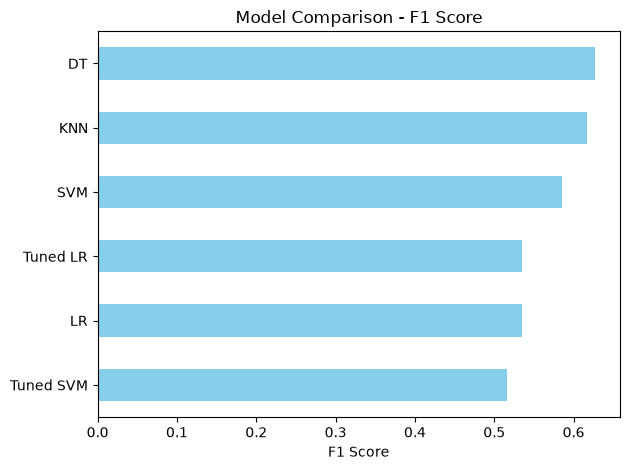

In [26]:
results_df.sort_values('F1')['F1'].plot(kind='barh', color='skyblue')
plt.title('Model Comparison - F1 Score')
plt.xlabel('F1 Score')
plt.tight_layout()
plt.show()

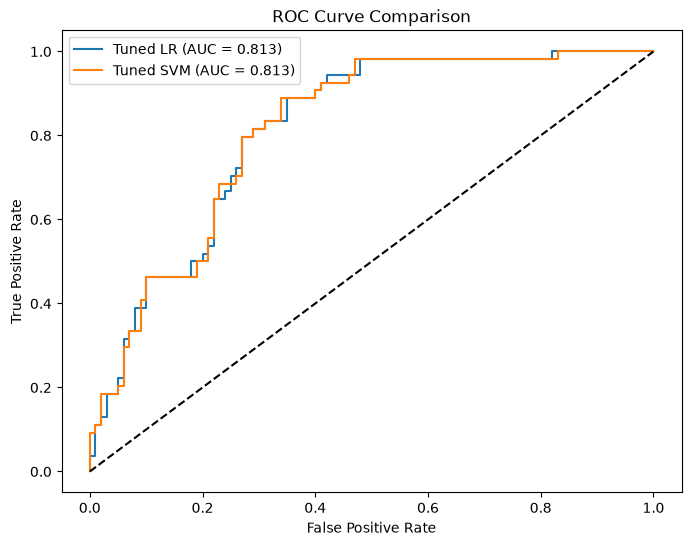

In [27]:
plt.figure(figsize=(8, 6))

models = {
    'Tuned LR': grid_lr.best_estimator_,
    'Tuned SVM': grid_svm.best_estimator_
}

for name, model in models.items():
    if hasattr(model, 'predict_proba'):
        y_prob = model.predict_proba(X_test_processed)[:, 1]
    else:
        y_prob = model.decision_function(X_test_processed)
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, y_prob):.3f})")

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.show()

## Best Model Selection
Selecting the best model based on F1-score and AUC.

In [28]:
best_model_name = results_df['F1'].idxmax()
print(f"Best model selected: {best_model_name} (F1={results_df.loc[best_model_name, 'F1']:.4f})")

# Build a fresh unified pipeline with the best classifier
if 'LR' in best_model_name:
    best_clf = LogisticRegression(random_state=42, max_iter=1000, **grid_lr.best_params_)
else:
    best_clf = SVC(probability=True, random_state=42, **grid_svm.best_params_)

final_pipeline = Pipeline([
    ('imputer', KNNImputer(n_neighbors=5)),
    ('scaler', StandardScaler()),
    ('classifier', best_clf)
])
final_pipeline.fit(X, y)  # train on full dataset

model_path = '/home/dau/AI/assign1/model/diabetes_model.pkl'
joblib.dump(final_pipeline, model_path)
print(f"Model saved to: {model_path}")

# Quick sanity check
sample = np.array([[6, 148, 72, 35, 0, 33.6, 0.627, 50]])
pred = final_pipeline.predict(sample)
prob = final_pipeline.predict_proba(sample)[0][1]
print(f"Sanity check — sample prediction: {pred[0]} (prob={prob:.3f})")

Best model selected: DT (F1=0.6271)


/home/dau/.conda/envs/assignment01/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Model saved to: /home/dau/AI/assign1/model/diabetes_model.pkl
Sanity check — sample prediction: 1 (prob=0.704)


/home/dau/.conda/envs/assignment01/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but KNNImputer was fitted with feature names
  warnings.warn(
/home/dau/.conda/envs/assignment01/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but KNNImputer was fitted with feature names
  warnings.warn(


## Conclusion
We successfully built an intelligent system for diabetes diagnosis using 8 features. We addressed missing data with KNN imputation, evaluated four models (LR, KNN, DT, SVM), tuned the hyperparameters, and saved the best performing model pipeline for future predictions.